In [1]:
import pandas as pd
import numpy as np
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
import gensim
import gensim.corpora as corpora
from gensim.models import LsiModel, CoherenceModel

In [2]:
df = pd.read_csv('IT_tickets2.csv')
df = df.rename(columns={'Unnamed: 0': 'id'})
df

,id,Document,Topic_group
0,25275,new purchase po wednesday november pm purchase...,Purchase
1,27632,license for tuesday october pm re starter form...,Access
2,14572,access to confluence to outside user pm re con...,Access
3,40979,not updating sent updating hello teams dear pl...,Hardware
4,41805,windows updates sent thursday re action requir...,Hardware
...,...,...,...
5975,16668,access to confluence thursday confluence hello...,Access
5976,18337,new project code oracle fusion tuesday march p...,Internal Project
5977,13962,maternity leaver hardware thursday re maternit...,HR Support
5978,37262,windows upgrade failed upgrade failed hi pleas...,Administrative rights


In [3]:
stoplist = stopwords.words('english')
lk = ['n', 'v', 'a', 'r', 's']

def preprocess_text(line):
    line = re.sub(r'[^\w\s\'’-]', '', line.strip())
    clean_line = " ".join([word for word in line.split() if word.lower() not in stoplist])
    
    lemmatizer = WordNetLemmatizer()
    words = word_tokenize(clean_line)
    pos_tagged = nltk.pos_tag(words)
    lemmatized_words = []

    for i, word in enumerate(words):
        word_pos = pos_tagged[i][1].lower() if pos_tagged[i][1].lower() in lk else 'n'
        lemmatized_words.append(lemmatizer.lemmatize(word.lower(), pos=word_pos))
    
    return " ".join(lemmatized_words)

In [4]:
# Попередня обробка тексту
df['processed_text'] = df['Document'].astype(str).apply(preprocess_text)

In [5]:
# Створення словника та корпусу
dictionary = corpora.Dictionary(df["processed_text"].apply(lambda x: x.split()))
corpus = [dictionary.doc2bow(text) for text in df["processed_text"].apply(lambda x: x.split())]

In [6]:
# Підбір оптимальної кількості тем для LSI
coherence_scores = []
models = []
topic_range = range(2, 11)

for num_topics in topic_range:
    lsi_model = LsiModel(
        corpus=corpus,
        id2word=dictionary,
        num_topics=num_topics,
        onepass=True,
        chunksize=1740,
        power_iters=1000
    )
    models.append(lsi_model)

    coherence_model = CoherenceModel(
        model=lsi_model,
        texts=df["processed_text"].apply(lambda x: x.split()),
        dictionary=dictionary,
        coherence='c_v'
    )
    coherence_scores.append(coherence_model.get_coherence())

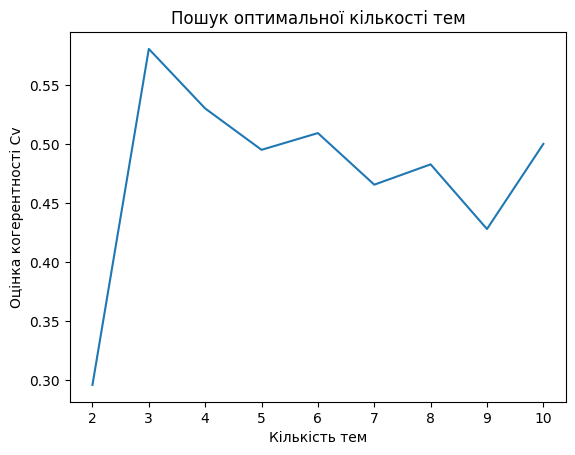

In [7]:
import matplotlib.pyplot as plt

plt.plot(topic_range, coherence_scores)
plt.xlabel("Кількість тем")
plt.ylabel("Оцінка когерентності Cv")
plt.title("Пошук оптимальної кількості тем")
plt.show()

In [8]:
best_index = coherence_scores.index(max(coherence_scores))
best_model = models[best_index]
best_num_topics = topic_range[best_index]
print("Найкраща кількість тем:", best_num_topics)

Найкраща кількість тем: 3


In [9]:
# Завдання 1а) Терми, що описують кожну з тем
for idx, topic in best_model.show_topics(num_topics=best_num_topics, num_words=10):
    print(f"Тема {idx + 1}:")
    print(topic)

Тема 1:
0.591*"please" + 0.252*"pm" + 0.246*"regard" + 0.222*"hi" + 0.201*"thank" + 0.195*"hello" + 0.133*"thanks" + 0.128*"sent" + 0.126*"kind" + 0.118*"issue"
Тема 2:
0.568*"interface" + 0.567*"changed" + 0.332*"link" + 0.261*"protocol" + 0.231*"switch" + 0.216*"stack" + -0.083*"please" + 0.081*"port" + 0.070*"peer" + 0.066*"event"
Тема 3:
-0.739*"sow" + -0.488*"pc" + -0.261*"propose" + -0.250*"approved" + -0.238*"executed" + -0.102*"renewal" + -0.051*"cover" + -0.041*"site" + -0.040*"expansion" + -0.034*"contract"


In [10]:
# Завдання 1б) Документи, що внесли найбільший вклад у кожну тему
doc_topic_matrix = np.zeros((len(corpus), best_num_topics))
for i, doc_bow in enumerate(corpus):
    doc_topics = best_model[doc_bow]
    for topic_id, weight in doc_topics:
        doc_topic_matrix[i, topic_id] = weight

for topic_id in range(best_num_topics):
    print(f"\n=== Тема {topic_id + 1} ===")
    top_doc_indices = np.argsort(np.abs(doc_topic_matrix[:, topic_id]))[::-1][:3]
    for doc_idx in top_doc_indices:
        print(f"Документ #{doc_idx} (Topic_group: {df.iloc[doc_idx]['Topic_group']})")
        print(f"  Текст: {df.iloc[doc_idx]['Document'][:200]}...")


=== Тема 1 ===
Документ #3897 (Topic_group: HR Support)
  Текст: to create with minus sr wednesday pm error expense report hello please assign thank best regards analyst wednesday pm re error expense report hello allow creation minus modified thank wednesday pm re ...
Документ #1259 (Topic_group: Hardware)
  Текст: initiative team shaping oracle pas pm initiative shaping hi please create relevant code offer cost recovery refers track formally please note present language drop down also part drop down find thanks...
Документ #1681 (Topic_group: Hardware)
  Текст: sr stack issues notification sr stack issues hello please kind help out by by pm kindest regards leader tuesday re sr stack issues hi thanks how issues translate user impact thrown please ensure advis...

=== Тема 2 ===
Документ #1681 (Topic_group: Hardware)
  Текст: sr stack issues notification sr stack issues hello please kind help out by by pm kindest regards leader tuesday re sr stack issues hi thanks how issues translate 

In [11]:
# Завдання 1в) Визначення тем для трьох нових документів
new_documents = [
    "I cannot access my email account. Please reset my password and grant me access to the system.",
    "The hard disk drive on my laptop has failed and I need a replacement device immediately, my computer is broken.",
    "I would like to purchase a new monitor and keyboard for my workstation, please process the purchase order."
]

new_processed = [preprocess_text(doc) for doc in new_documents]
new_corpus = [dictionary.doc2bow(text.split()) for text in new_processed]

for i, doc_bow in enumerate(new_corpus):
    doc_topics = best_model[doc_bow]
    topic_weights = [0.0] * best_num_topics
    for topic_id, weight in doc_topics:
        topic_weights[topic_id] = weight
    dominant_topic = int(np.argmax(np.abs(topic_weights)))
    print(f"\nДокумент {i + 1}: {new_documents[i]}")
    print(f"  Домінуюча тема: {dominant_topic + 1}")
    print(f"  Розподіл по темах: {[round(w, 3) for w in topic_weights]}")


Документ 1: I cannot access my email account. Please reset my password and grant me access to the system.
  Домінуюча тема: 1
  Розподіл по темах: [0.853, -0.129, 0.037]

Документ 2: The hard disk drive on my laptop has failed and I need a replacement device immediately, my computer is broken.
  Домінуюча тема: 1
  Розподіл по темах: [0.125, -0.021, -0.037]

Документ 3: I would like to purchase a new monitor and keyboard for my workstation, please process the purchase order.
  Домінуюча тема: 1
  Розподіл по темах: [0.802, -0.113, 0.027]


In [12]:
from nltk.corpus import gutenberg
from nltk.collocations import TrigramCollocationFinder, TrigramAssocMeasures

In [15]:
# Завдання 2 - Робота з текстом chesterton-brown.txt
text = gutenberg.raw('chesterton-brown.txt')

tokens = word_tokenize(text.lower())
stop_words = set(stopwords.words('english'))

tokens = [word for word in tokens if word.isalpha() and word not in stop_words]

In [17]:
trigram_measures = TrigramAssocMeasures()
finder = TrigramCollocationFinder.from_words(tokens)
top_trigrams = finder.nbest(trigram_measures.pmi, 10)

In [18]:
for trigram in top_trigrams:
    print(trigram)

('abandoned', 'abstract', 'meditations')
('abstraction', 'lesser', 'gem')
('academy', 'project', 'bimetallism')
('anarchist', 'antipatriot', 'views')
('anglian', 'plains', 'seawards')
('attitudes', 'aptly', 'tested')
('bismarck', 'earliest', 'schemes')
('bleak', 'offices', 'yawning')
('campaign', 'swift', 'precision')
('causing', 'stagger', 'swing')
